## Forest Cover Type Prediction

## Project Objective

The objective of this project is to predict seven different forest cover types
in four different wilderness areas of the Roosevelt National Forest of
Northern Colorado.

This project includes:
1. Data loading
2. Data understanding
3. Exploratory Data Analysis
4. Data preprocessing
5. Feature engineering
6. Model building
7. Model evaluation
8. Hyperparameter tuning
9. Model comparison
10. Challenges and solutions
11. Final conclusion

In [1]:
### important libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
classification_report,
confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"train.csv")

In [3]:
df.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15120 non-null  int64
 12  Wild

In [5]:
df.describe()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,15120.00000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,...,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000
mean,7560.50000,2749.322553,156.676653,16.501587,227.195701,51.076521,1714.023214,212.704299,218.965608,135.091997,...,0.045635,0.040741,0.001455,0.006746,0.000661,0.002249,0.048148,0.043452,0.030357,4.000000
std,4364.91237,417.678187,110.085801,8.453927,210.075296,61.239406,1325.066358,30.561287,22.801966,45.895189,...,0.208699,0.197696,0.038118,0.081859,0.025710,0.047368,0.214086,0.203880,0.171574,2.000066
min,1.00000,1863.000000,0.000000,0.000000,0.000000,-146.000000,0.000000,0.000000,99.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,3780.75000,2376.000000,65.000000,10.000000,67.000000,5.000000,764.000000,196.000000,207.000000,106.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,7560.50000,2752.000000,126.000000,15.000000,180.000000,32.000000,1316.000000,220.000000,223.000000,138.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,11340.25000,3104.000000,261.000000,22.000000,330.000000,79.000000,2270.000000,235.000000,235.000000,167.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000
max,15120.00000,3849.000000,360.000000,52.000000,1343.000000,554.000000,6890.000000,254.000000,254.000000,248.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


In [6]:
df.dtypes

Id                                    int64
Elevation                             int64
Aspect                                int64
Slope                                 int64
Horizontal_Distance_To_Hydrology      int64
Vertical_Distance_To_Hydrology        int64
Horizontal_Distance_To_Roadways       int64
Hillshade_9am                         int64
Hillshade_Noon                        int64
Hillshade_3pm                         int64
Horizontal_Distance_To_Fire_Points    int64
Wilderness_Area1                      int64
Wilderness_Area2                      int64
Wilderness_Area3                      int64
Wilderness_Area4                      int64
Soil_Type1                            int64
Soil_Type2                            int64
Soil_Type3                            int64
Soil_Type4                            int64
Soil_Type5                            int64
Soil_Type6                            int64
Soil_Type7                            int64
Soil_Type8                      

In [7]:
df.columns

Index(['Id', 'Elevation', 'Aspect', 'Slope',
       'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
       'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon',
       'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points',
       'Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3',
       'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3',
       'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8',
       'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12',
       'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16',
       'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20',
       'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24',
       'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28',
       'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32',
       'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36',
       'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_

In [8]:
df.shape

(15120, 56)

## Checking Missing Values

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.nunique()

Id                                    15120
Elevation                              1665
Aspect                                  361
Slope                                    52
Horizontal_Distance_To_Hydrology        400
Vertical_Distance_To_Hydrology          423
Horizontal_Distance_To_Roadways        3250
Hillshade_9am                           176
Hillshade_Noon                          141
Hillshade_3pm                           247
Horizontal_Distance_To_Fire_Points     2710
Wilderness_Area1                          2
Wilderness_Area2                          2
Wilderness_Area3                          2
Wilderness_Area4                          2
Soil_Type1                                2
Soil_Type2                                2
Soil_Type3                                2
Soil_Type4                                2
Soil_Type5                                2
Soil_Type6                                2
Soil_Type7                                1
Soil_Type8                      

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.drop_duplicates().reset_index(drop=True)
df.duplicated().sum()

np.int64(0)

In [13]:
df.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


## Check Traget Variables

In [14]:
df["Cover_Type"].value_counts().sort_index()

Cover_Type
1    2160
2    2160
3    2160
4    2160
5    2160
6    2160
7    2160
Name: count, dtype: int64

In [15]:
print("Number of cover types:",df["Cover_Type"].nunique())

Number of cover types: 7


In [16]:
df["Cover_Type"].unique()

array([5, 2, 1, 7, 3, 6, 4])

## Visualize Target Distribution

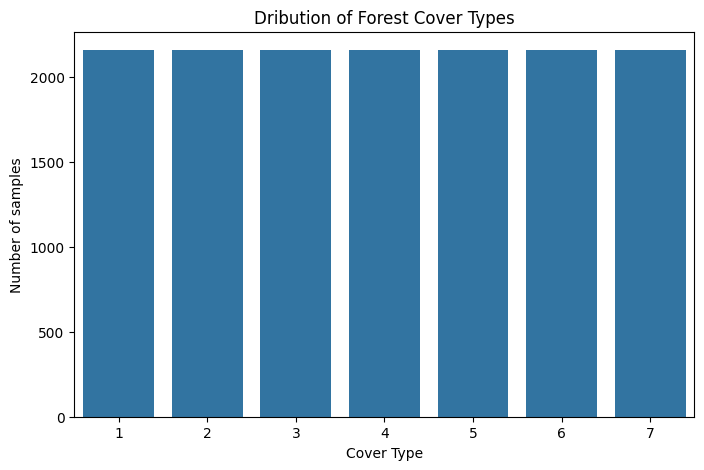

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="Cover_Type"
)

plt.title("Dribution of Forest Cover Types")
plt.xlabel("Cover Type")
plt.ylabel("Number of samples")

plt.show()

In [18]:
numerical_columns = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

In [19]:
df[numerical_columns].describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
count,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000
mean,2749.322553,156.676653,16.501587,227.195701,51.076521,1714.023214,212.704299,218.965608,135.091997,1511.147288
std,417.678187,110.085801,8.453927,210.075296,61.239406,1325.066358,30.561287,22.801966,45.895189,1099.936493
min,1863.000000,0.000000,0.000000,0.000000,-146.000000,0.000000,0.000000,99.000000,0.000000,0.000000
25%,2376.000000,65.000000,10.000000,67.000000,5.000000,764.000000,196.000000,207.000000,106.000000,730.000000
50%,2752.000000,126.000000,15.000000,180.000000,32.000000,1316.000000,220.000000,223.000000,138.000000,1256.000000
75%,3104.000000,261.000000,22.000000,330.000000,79.000000,2270.000000,235.000000,235.000000,167.000000,1988.250000
max,3849.000000,360.000000,52.000000,1343.000000,554.000000,6890.000000,254.000000,254.000000,248.000000,6993.000000


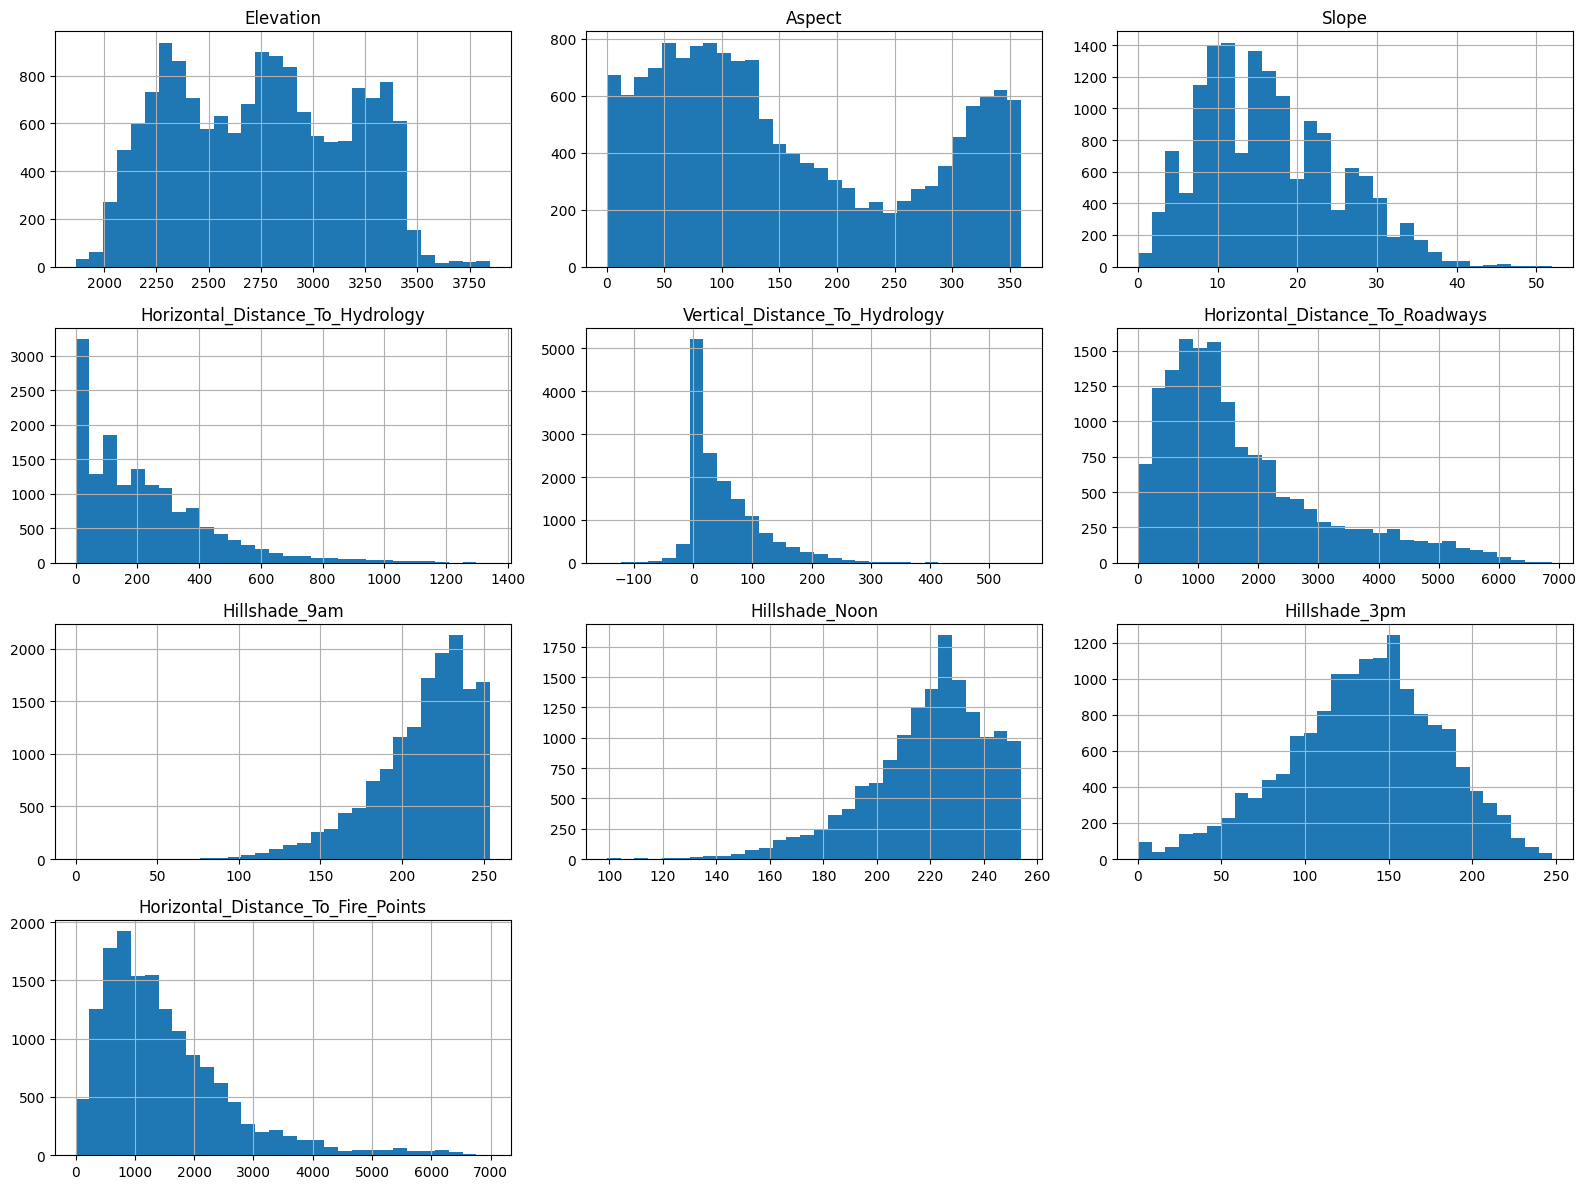

In [20]:
df[numerical_columns].hist(
    figsize=(16,12),
    bins=30
)
plt.tight_layout()
plt.show()

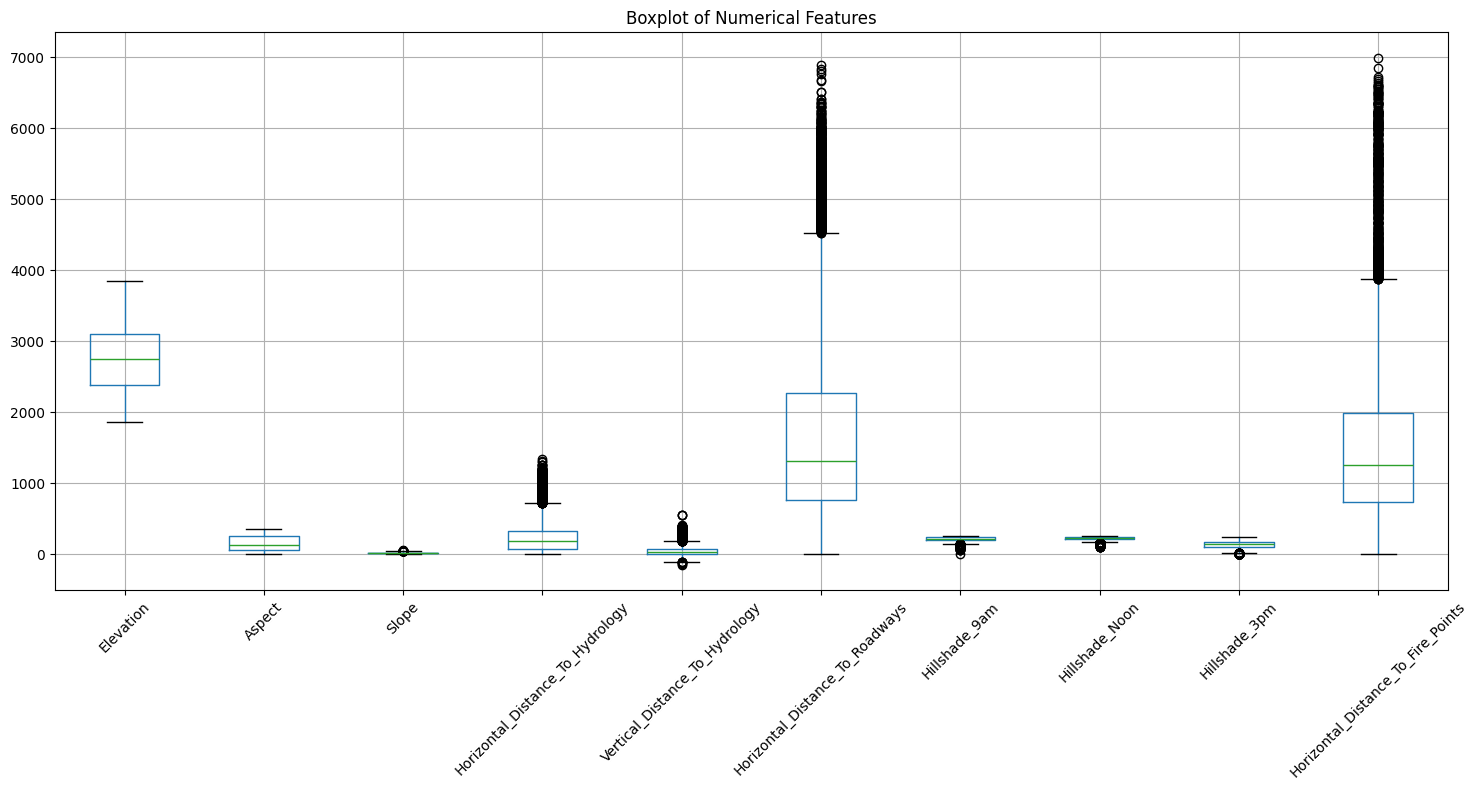

In [21]:
plt.figure(figsize=(15,8))
df[numerical_columns].boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.tight_layout()
plt.show()

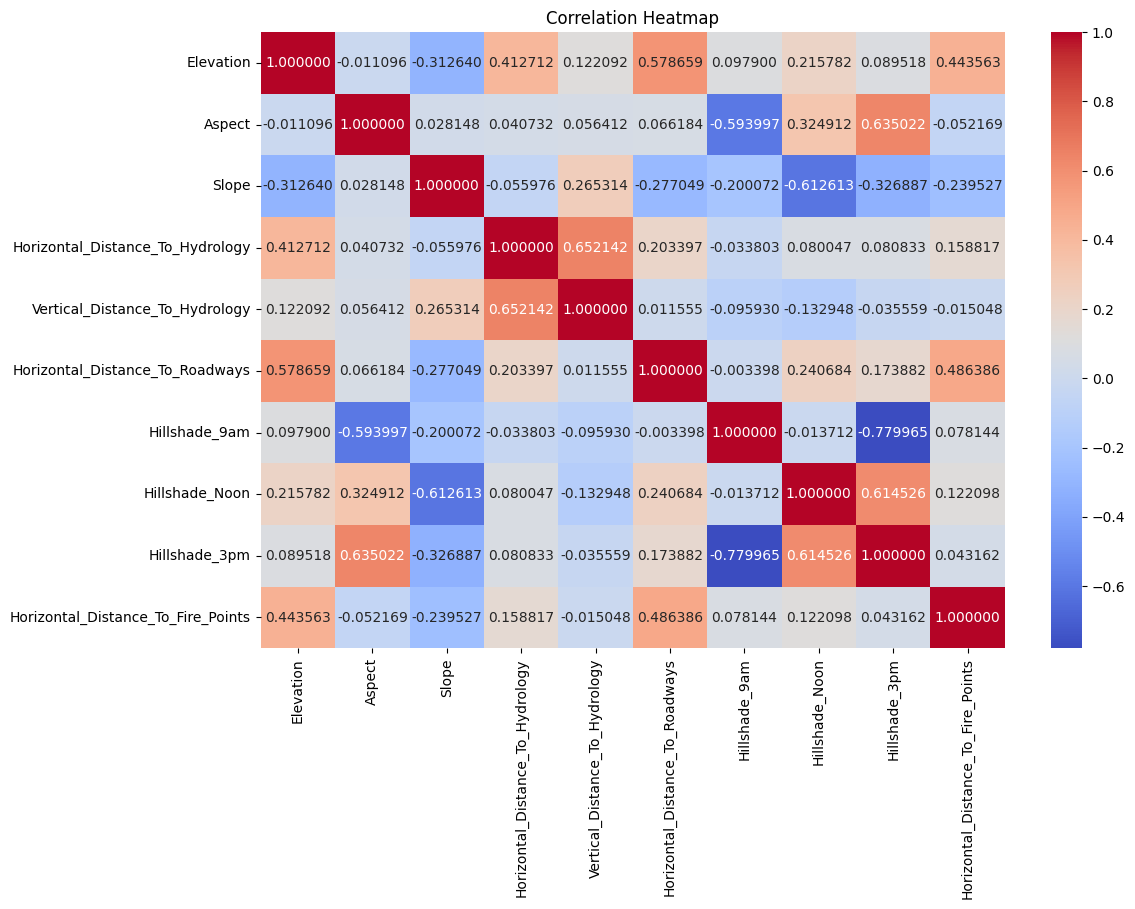

In [22]:
correlation = df[numerical_columns].corr()
plt.figure(figsize=(12,8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt="2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [23]:
wilderness_columns = [
    col for col in df.columns
    if col.startswith("Wilderness_Area")
]
wilderness_columns

['Wilderness_Area1',
 'Wilderness_Area2',
 'Wilderness_Area3',
 'Wilderness_Area4']

In [24]:
df[wilderness_columns].sum()

Wilderness_Area1    3597
Wilderness_Area2     499
Wilderness_Area3    6349
Wilderness_Area4    4675
dtype: int64

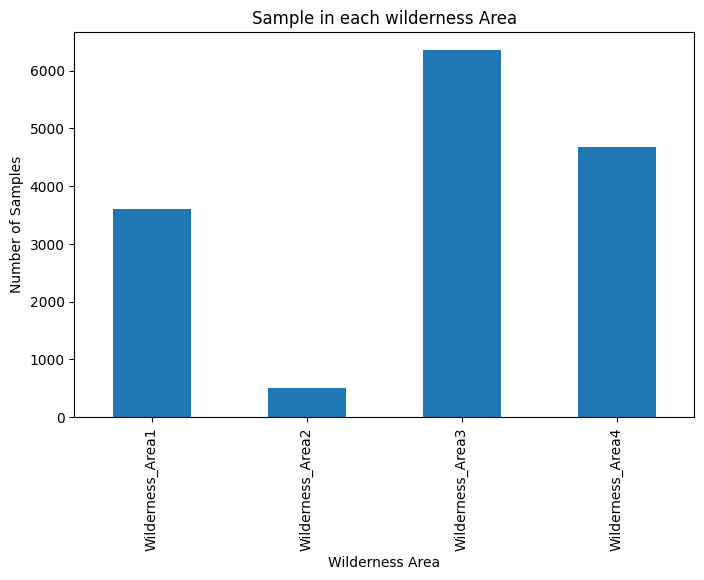

In [25]:
df[wilderness_columns].sum().plot(
    kind="bar",
    figsize=(8,5)
)
plt.title("Sample in each wilderness Area")
plt.xlabel("Wilderness Area")
plt.ylabel("Number of Samples")
plt.show()

In [26]:
soil_columns = [
    c for c in df.columns
    if c.startswith("Soil_type")
]
print("Number of soil column:",len(soil_columns))

Number of soil column: 0


In [27]:
df[soil_columns].sum().sort_values(ascending=False).head(10)

Series([], dtype: float64)

## Train Test split

In [28]:
x = df.drop("Cover_Type",axis=1)
y = df["Cover_Type"]

In [29]:
x.shape

(15120, 55)

In [30]:
y.shape

(15120,)

In [31]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## Feature Scaling

In [32]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## Models

In [33]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
logistic_model.fit(x_train_scaled,y_train)
logistic_pred = logistic_model.predict(x_test_scaled)

In [34]:
print(
    classification_report(
        y_test,
        logistic_pred
    )
)

              precision    recall  f1-score   support

           1       0.64      0.68      0.66       432
           2       0.59      0.50      0.54       432
           3       0.59      0.52      0.55       432
           4       0.82      0.87      0.85       432
           5       0.72      0.75      0.74       432
           6       0.58      0.65      0.61       432
           7       0.88      0.87      0.87       432

    accuracy                           0.69      3024
   macro avg       0.69      0.69      0.69      3024
weighted avg       0.69      0.69      0.69      3024



In [35]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)
decision_tree.fit(
    x_train,
    y_train
)
dt_pred = decision_tree.predict(
    x_test
)

In [36]:
print(classification_report(y_test,dt_pred))

              precision    recall  f1-score   support

           1       0.68      0.65      0.66       432
           2       0.62      0.62      0.62       432
           3       0.77      0.76      0.76       432
           4       0.91      0.92      0.91       432
           5       0.85      0.89      0.87       432
           6       0.81      0.80      0.81       432
           7       0.91      0.92      0.91       432

    accuracy                           0.79      3024
   macro avg       0.79      0.79      0.79      3024
weighted avg       0.79      0.79      0.79      3024



In [37]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs =-1
)
random_forest.fit(
    x_train,
    y_train
)
rf_pred = random_forest.predict(x_test)

In [38]:
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           1       0.78      0.78      0.78       432
           2       0.80      0.65      0.72       432
           3       0.83      0.81      0.82       432
           4       0.94      0.98      0.96       432
           5       0.89      0.96      0.92       432
           6       0.83      0.87      0.85       432
           7       0.93      0.97      0.95       432

    accuracy                           0.86      3024
   macro avg       0.86      0.86      0.86      3024
weighted avg       0.86      0.86      0.86      3024



In [39]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train_scaled,y_train)
knn_pred = knn_model.predict(x_test_scaled)

In [40]:
print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           1       0.69      0.67      0.68       432
           2       0.66      0.53      0.58       432
           3       0.70      0.65      0.68       432
           4       0.87      0.95      0.91       432
           5       0.79      0.88      0.83       432
           6       0.70      0.74      0.72       432
           7       0.93      0.95      0.94       432

    accuracy                           0.77      3024
   macro avg       0.76      0.77      0.76      3024
weighted avg       0.76      0.77      0.76      3024



In [41]:
svm_model = SVC(kernel="rbf")
svm_model.fit(x_train_scaled,y_train)
svm_pred = svm_model.predict(x_test_scaled)

In [42]:
print(classification_report(y_test,svm_pred))

              precision    recall  f1-score   support

           1       0.65      0.70      0.68       432
           2       0.62      0.54      0.58       432
           3       0.66      0.59      0.62       432
           4       0.82      0.95      0.88       432
           5       0.76      0.77      0.77       432
           6       0.64      0.66      0.65       432
           7       0.92      0.86      0.89       432

    accuracy                           0.73      3024
   macro avg       0.72      0.73      0.72      3024
weighted avg       0.72      0.73      0.72      3024



In [43]:
print(classification_report(y_test,svm_pred))

              precision    recall  f1-score   support

           1       0.65      0.70      0.68       432
           2       0.62      0.54      0.58       432
           3       0.66      0.59      0.62       432
           4       0.82      0.95      0.88       432
           5       0.76      0.77      0.77       432
           6       0.64      0.66      0.65       432
           7       0.92      0.86      0.89       432

    accuracy                           0.73      3024
   macro avg       0.72      0.73      0.72      3024
weighted avg       0.72      0.73      0.72      3024



In [44]:
gradient_model = GradientBoostingClassifier(random_state=42)
gradient_model.fit(x_train,y_train)
gradient_pred = gradient_model.predict(x_test)

In [45]:
print(classification_report(y_test,gradient_pred))

              precision    recall  f1-score   support

           1       0.73      0.72      0.73       432
           2       0.75      0.56      0.64       432
           3       0.74      0.75      0.74       432
           4       0.93      0.95      0.94       432
           5       0.81      0.93      0.86       432
           6       0.76      0.79      0.78       432
           7       0.91      0.96      0.93       432

    accuracy                           0.81      3024
   macro avg       0.80      0.81      0.80      3024
weighted avg       0.80      0.81      0.80      3024



## Model Comparison

In [46]:
model = {
    "Logistic Regression": (y_test,logistic_pred),
    "Decision Tree": (y_test,dt_pred),
    "Random Forest": (y_test,rf_pred),
    "KNN": (y_test,knn_pred),
    "SVM": (y_test,svm_pred),
    "Gradient Boosting": (y_test,gradient_pred)
}

In [47]:
result = []
for model_name,(actual,predicted) in model.items():
    accuracy = accuracy_score(
        actual,predicted
    )
    precision = precision_score(
        actual,predicted,average="weighted"
    )
    recall = recall_score(
        actual,predicted,average="weighted"
    )
    f1 = f1_score(
        actual,predicted,average="weighted"
    )
    result.append({
        "Model":model_name,
        "Accuracy":accuracy,
        "Precision":precision,
        "Recall":recall,
        "F1 Score":f1
    })

result_df = pd.DataFrame(result)
result_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.691799,0.689180,0.691799,0.689118
1,Decision Tree,0.792989,0.791493,0.792989,0.792115
2,Random Forest,0.859788,0.857037,0.859788,0.857055
3,KNN,0.767526,0.761733,0.767526,0.762786
4,SVM,0.726190,0.723978,0.726190,0.723398
5,Gradient Boosting,0.807540,0.804424,0.807540,0.803373


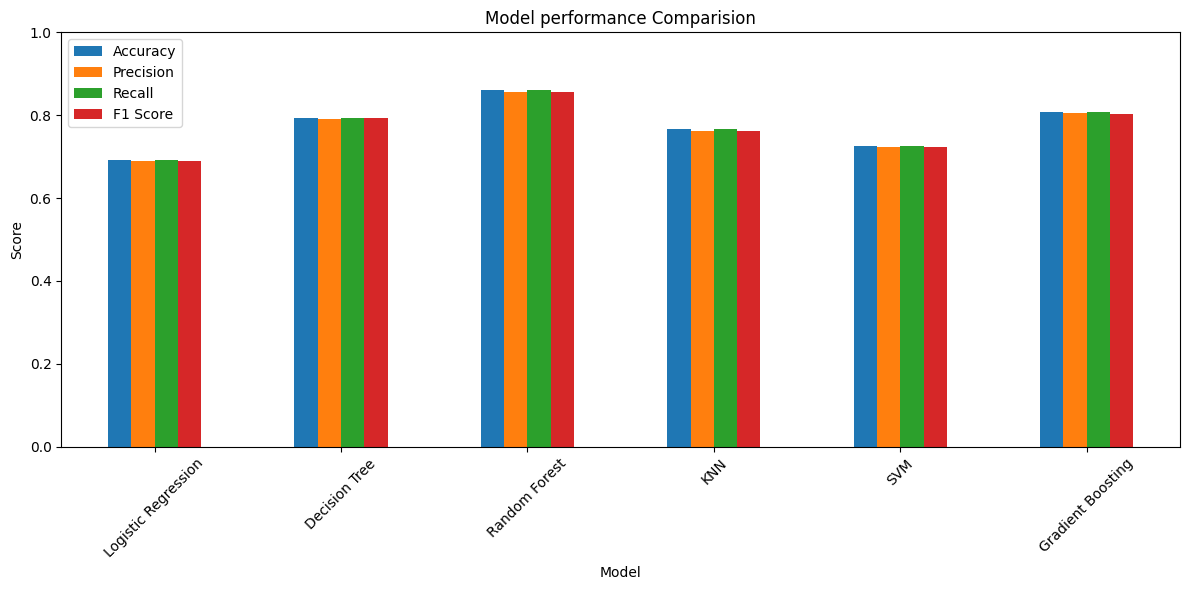

In [48]:
result_df.set_index("Model")[
    ["Accuracy","Precision","Recall","F1 Score"]
].plot(
    kind="bar",
    figsize=(12,6)
)
plt.title("Model performance Comparision")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

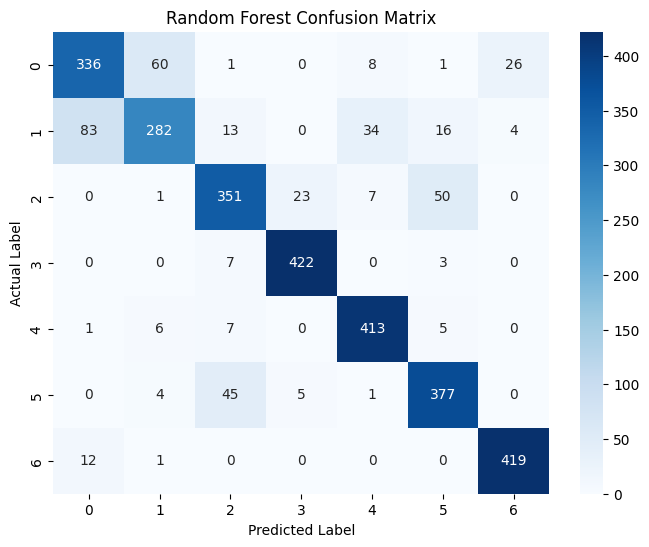

In [49]:
cm = confusion_matrix(
    y_test,rf_pred
)
plt.figure(figsize=(8,6))
sns.heatmap(
    cm,annot=True,fmt="d",cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [50]:
feature_importance = pd.DataFrame({
    "Feature":x.columns,
    "Importance":random_forest.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
feature_importance.head(20)

,Feature,Importance
1,Elevation,0.210094
6,Horizontal_Distance_To_Roadways,0.084062
0,Id,0.076682
10,Horizontal_Distance_To_Fire_Points,0.064934
4,Horizontal_Distance_To_Hydrology,0.054717
5,Vertical_Distance_To_Hydrology,0.050021
7,Hillshade_9am,0.048656
14,Wilderness_Area4,0.048603
2,Aspect,0.044713
9,Hillshade_3pm,0.041264


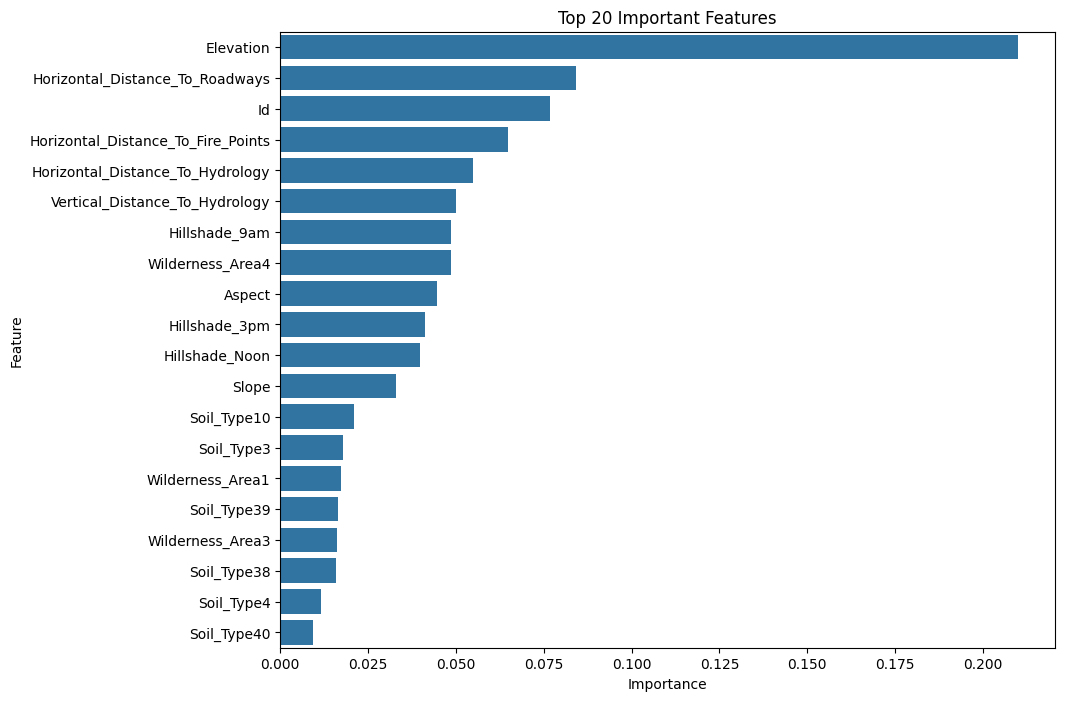

In [51]:
plt.figure(figsize=(10,8))
sns.barplot(
    data=feature_importance.head(20),
    x="Importance",
    y="Feature"
)
plt.title("Top 20 Important Features")
plt.show()

In [52]:
from sklearn.model_selection import GridSearchCV

In [53]:
param_grid = {
    "n_estimators":[100,200],
    "max_depth":[None,20,30],
    "min_samples_split":[2,5],
    "min_samples_leaf":[1,2]
}

In [54]:
grid_search = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1,
    verbose=1
)

In [55]:
grid_search.fit(x_train,y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'accuracy'
,n_jobs,1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [56]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [57]:
print("Best Cross Validation Score:")
print(grid_search.best_score_)

Best Cross Validation Score:
0.8568948412698413


In [58]:
best_model = grid_search.best_estimator_
best_pred = best_model.predict(x_test)

In [59]:
print(classification_report(y_test,best_pred))

              precision    recall  f1-score   support

           1       0.80      0.78      0.79       432
           2       0.81      0.68      0.74       432
           3       0.85      0.82      0.83       432
           4       0.94      0.98      0.96       432
           5       0.89      0.95      0.92       432
           6       0.84      0.90      0.87       432
           7       0.94      0.97      0.95       432

    accuracy                           0.87      3024
   macro avg       0.87      0.87      0.87      3024
weighted avg       0.87      0.87      0.87      3024



## Final Model Metrics

In [60]:
final_accuracy = accuracy_score(
    y_test,
    best_pred
)
final_precision = precision_score(
    y_test,
    best_pred,
    average="weighted"
)
final_recall = recall_score(
    y_test,
    best_pred,
    average="weighted"
)
final_f1 = f1_score(
    y_test,
    best_pred,
    average="weighted"
)
print("Accuracy:",final_accuracy)
print("Precision:",final_precision)
print("Recall:",final_recall)
print("F1:",final_f1)

Accuracy: 0.8687169312169312
Precision: 0.866342542970844
Recall: 0.8687169312169312
F1: 0.8662763691167004


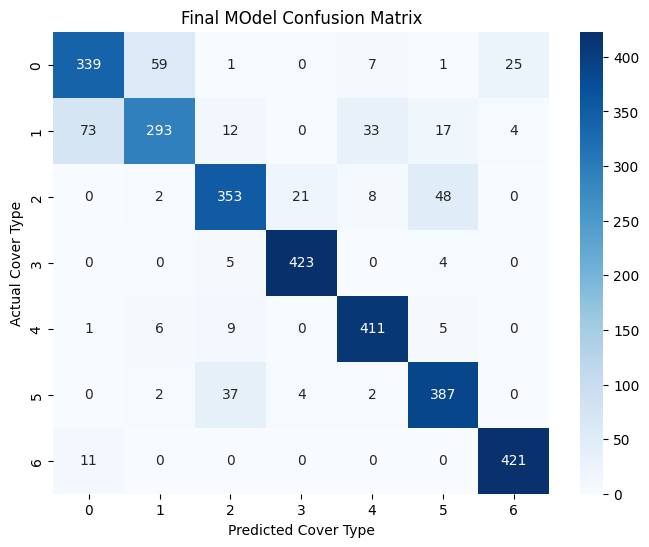

In [61]:
cm = confusion_matrix(
    y_test,
    best_pred
)
plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Final MOdel Confusion Matrix")
plt.xlabel("Predicted Cover Type")
plt.ylabel("Actual Cover Type")
plt.show()

In [62]:
print(classification_report(y_test,best_pred))

              precision    recall  f1-score   support

           1       0.80      0.78      0.79       432
           2       0.81      0.68      0.74       432
           3       0.85      0.82      0.83       432
           4       0.94      0.98      0.96       432
           5       0.89      0.95      0.92       432
           6       0.84      0.90      0.87       432
           7       0.94      0.97      0.95       432

    accuracy                           0.87      3024
   macro avg       0.87      0.87      0.87      3024
weighted avg       0.87      0.87      0.87      3024



## Challenges
Handling a dataset with many features.

Scaling features for some machine learning models.

Classifying seven different forest cover types.

Comparing multiple machine learning algorithms.

Finding suitable hyperparameters for better performance.

## Limitations
Dataset is limited to a specific geographical region.

Other environmental factors such as weather are not included.

Model accuracy is not 100%.

Performance depends on the quality of the dataset.

## Conclusion

The project successfully predicted forest cover types using machine learning. Different classification algorithms were compared, and Random Forest achieved the best performance with about 85.98% accuracy. The project demonstrates that machine learning can be effectively used for forest cover classification.